# Qwen3 correlations from repaired reconstructions

This notebook analyzes the Qwen3 Base reconstruction sweep across decoder sizes **0.6B, 1.7B, and 4B** and representations `4096_last`, `4096_avg`, `4x4096_avg`, `16x4096_avg`, and `64x4096_avg`.

The data below are rebuilt from every matched raw `*_reconstructed.json` prediction. Each prediction is parsed, repaired with `json_repair` when necessary, has degenerate component loops collapsed, and is rescored against the cleaned RICO hierarchy through the same `repair_rescore.py` and `reconstruction_metrics.py` path used by `_results_reconstruction.ipynb`. Strict and repaired results are not mixed.

The primary outcome is **repaired unordered class F1**. Correlations and plots are also produced for the other repaired reconstruction-quality metrics reported by `_results_reconstruction.ipynb`.

In [1]:
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import rankdata
from tqdm.auto import tqdm

import repair_rescore

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)

MODEL_SIZES = [0.6, 1.7, 4.0]
POOL_ORDER = ["4096_last", "4096_avg", "4x4096_avg", "16x4096_avg", "64x4096_avg"]
POOL_TOKENS = {"4096_last": 1, "4096_avg": 1, "4x4096_avg": 4, "16x4096_avg": 16, "64x4096_avg": 64}
POOL_LABELS = {name: name.replace("_", " ") for name in POOL_ORDER}

COLLAPSE_LOOPS = True  # match the complete repair pass in _results_reconstruction.ipynb
MAX_WORKERS = None
N_PERMUTATIONS = 10_000
PERMUTATION_BATCH_SIZE = 100
RANDOM_SEED = 20260905

## Repaired metrics

Component counts, repair-use flags, and collapsed-loop counts are retained as diagnostics but are not treated as quality metrics. Levenshtein distance is omitted because its similarity counterpart is easier to interpret.

In [2]:
METRICS = {
    "class_unordered_f1_repaired": "Unordered class F1 (repaired)",
    "class_unordered_recall_repaired": "Unordered class recall (repaired)",
    "class_unordered_precision_repaired": "Unordered class precision (repaired)",
    "class_level_f1_repaired": "Depth-aware class F1 (repaired)",
    "class_level_recall_repaired": "Depth-aware class recall (repaired)",
    "class_level_precision_repaired": "Depth-aware class precision (repaired)",
    "matched_iou_repaired": "Matched bounds IoU (repaired)",
    "class_accuracy_repaired": "Positional class accuracy (repaired)",
    "average_bounds_iou_repaired": "Positional average bounds IoU (repaired)",
    "levenshtein_similarity_repaired": "Levenshtein similarity (repaired)",
    "json_valid_repaired": "Valid JSON after repair",
    "app_match_repaired": "App match after repair",
    "activity_match_repaired": "Activity match after repair",
}
PRIMARY_METRIC = "class_unordered_f1_repaired"
list(METRICS.items())

[('class_unordered_f1_repaired', 'Unordered class F1 (repaired)'),
 ('class_unordered_recall_repaired', 'Unordered class recall (repaired)'),
 ('class_unordered_precision_repaired',
  'Unordered class precision (repaired)'),
 ('class_level_f1_repaired', 'Depth-aware class F1 (repaired)'),
 ('class_level_recall_repaired', 'Depth-aware class recall (repaired)'),
 ('class_level_precision_repaired', 'Depth-aware class precision (repaired)'),
 ('matched_iou_repaired', 'Matched bounds IoU (repaired)'),
 ('class_accuracy_repaired', 'Positional class accuracy (repaired)'),
 ('average_bounds_iou_repaired', 'Positional average bounds IoU (repaired)'),
 ('levenshtein_similarity_repaired', 'Levenshtein similarity (repaired)'),
 ('json_valid_repaired', 'Valid JSON after repair'),
 ('app_match_repaired', 'App match after repair'),
 ('activity_match_repaired', 'Activity match after repair')]

## Discover the complete 3 × 5 design

In [3]:
experiment_re = re.compile(
    r"^reconstructions_(?P<pool>4096_(?:last|avg)|(?:4|16|64)x4096_avg)"
    r"__via__embeddings_(?P=pool)_full_qwen3-(?P<size>0\.6|1\.7|4)b-base$"
)

experiment_rows = []
for directory in Path(".").glob("reconstructions_*qwen3-*-base"):
    match = experiment_re.match(directory.name)
    if match is None:
        continue
    pooling = match.group("pool")
    experiment_rows.append({
        "model_size_b": float(match.group("size")),
        "pooling": pooling,
        "pool_tokens": POOL_TOKENS[pooling],
        "embedding_dims": 4096 * POOL_TOKENS[pooling],
        "directory": directory,
        "dim": directory.name.removeprefix("reconstructions_"),
    })

experiments = pd.DataFrame(experiment_rows).sort_values(["model_size_b", "pool_tokens", "pooling"]).reset_index(drop=True)
expected = {(size, pool) for size in MODEL_SIZES for pool in POOL_ORDER}
found = set(zip(experiments["model_size_b"], experiments["pooling"]))
assert found == expected, f"Missing={sorted(expected - found)}; unexpected={sorted(found - expected)}"
assert not experiments.duplicated(["model_size_b", "pooling"]).any()
experiments

,model_size_b,pooling,pool_tokens,embedding_dims,directory,dim
0,0.6,4096_avg,1,4096,reconstructions_4096_avg__via__embeddings_4096...,4096_avg__via__embeddings_4096_avg_full_qwen3-...
1,0.6,4096_last,1,4096,reconstructions_4096_last__via__embeddings_409...,4096_last__via__embeddings_4096_last_full_qwen...
2,0.6,4x4096_avg,4,16384,reconstructions_4x4096_avg__via__embeddings_4x...,4x4096_avg__via__embeddings_4x4096_avg_full_qw...
3,0.6,16x4096_avg,16,65536,reconstructions_16x4096_avg__via__embeddings_1...,16x4096_avg__via__embeddings_16x4096_avg_full_...
4,0.6,64x4096_avg,64,262144,reconstructions_64x4096_avg__via__embeddings_6...,64x4096_avg__via__embeddings_64x4096_avg_full_...
5,1.7,4096_avg,1,4096,reconstructions_4096_avg__via__embeddings_4096...,4096_avg__via__embeddings_4096_avg_full_qwen3-...
6,1.7,4096_last,1,4096,reconstructions_4096_last__via__embeddings_409...,4096_last__via__embeddings_4096_last_full_qwen...
7,1.7,4x4096_avg,4,16384,reconstructions_4x4096_avg__via__embeddings_4x...,4x4096_avg__via__embeddings_4x4096_avg_full_qw...
8,1.7,16x4096_avg,16,65536,reconstructions_16x4096_avg__via__embeddings_1...,16x4096_avg__via__embeddings_16x4096_avg_full_...
9,1.7,64x4096_avg,64,262144,reconstructions_64x4096_avg__via__embeddings_6...,64x4096_avg__via__embeddings_64x4096_avg_full_...


## Match screens across all experiments

Several 4B jobs are incomplete and cover different subsets. Only raw reconstructions present in every experiment are retained, preventing population differences from masquerading as model effects.

In [4]:
def reconstruction_ids(directory: Path) -> set[str]:
    return {path.stem.removesuffix("_reconstructed") for path in directory.glob("*_reconstructed.json")}

largest_model_dirs = experiments.loc[experiments["model_size_b"].eq(max(MODEL_SIZES)), "directory"]
candidate_ids = set.intersection(*(reconstruction_ids(path) for path in largest_model_dirs))
common_ids = {
    screen_id for screen_id in candidate_ids
    if all((directory / f"{screen_id}_reconstructed.json").is_file() for directory in experiments["directory"])
}
common_ids = sorted(common_ids, key=int)
assert common_ids, "No raw reconstructions are shared by all 15 experiments."
print(f"Matched population: {len(common_ids):,} screens × {len(experiments)} experiments")

Matched population: 453 screens × 15 experiments


## Repair and rescore the raw reconstructions

`only_invalid=False` is essential because valid JSON can contain repeated loops too. Ground truth is loaded and cleaned once per screen, then shared across its 15 predictions.

In [5]:
base_rows = [
    {
        "dim": experiment.dim,
        "idx": screen_id,
        "json_path": str(Path("../rico-data/data/layouts") / f"{screen_id}.json"),
        "json_valid": None,
    }
    for experiment in experiments.itertuples(index=False)
    for screen_id in common_ids
]
rescore_input = pd.DataFrame(base_rows).set_index(["dim", "idx"])
tasks = repair_rescore.build_tasks(rescore_input, only_invalid=False)
assert len(tasks) == len(common_ids)
print(f"Repairing and rescoring {len(rescore_input):,} raw reconstructions in {len(tasks):,} paired tasks")

Repairing and rescoring 6,795 raw reconstructions in 453 paired tasks


In [6]:
rescored_rows = []
with ProcessPoolExecutor(
    max_workers=MAX_WORKERS,
    initializer=repair_rescore.init_worker,
    initargs=(COLLAPSE_LOOPS,),
) as pool:
    for screen_rows in tqdm(
        pool.map(repair_rescore.rescore_item, tasks, chunksize=8),
        total=len(tasks),
        desc="repair + rescore",
    ):
        rescored_rows.extend(screen_rows)

rescored = pd.DataFrame(rescored_rows)
if "rescore_error" in rescored:
    failures = rescored[rescored["rescore_error"].notna()]
    assert failures.empty, failures[["dim", "idx", "rescore_error"]].head()

analysis = rescored.merge(
    experiments[["dim", "model_size_b", "pooling", "pool_tokens", "embedding_dims"]],
    on="dim", validate="many_to_one",
)
analysis["screen_id"] = analysis["idx"].astype(int)
for metric in METRICS:
    analysis[metric] = pd.to_numeric(analysis[metric], errors="coerce")
assert len(analysis) == len(common_ids) * len(experiments)
assert analysis[list(METRICS)].notna().all().all()
analysis = analysis.sort_values(["screen_id", "pooling", "model_size_b"]).reset_index(drop=True)
print(f"Analysis rows: {len(analysis):,}")
analysis.head()

repair + rescore:   0%|          | 0/453 [00:00<?, ?it/s]

Analysis rows: 6,795


,dim,idx,json_valid_repaired,json_repair_used,components_collapsed,levenshtein_distance_repaired,levenshtein_similarity_repaired,app_match_repaired,activity_match_repaired,component_count_gt_repaired,component_count_pred_repaired,class_accuracy_repaired,average_bounds_iou_repaired,class_unordered_recall,class_unordered_recall_repaired,class_unordered_precision,class_unordered_precision_repaired,class_unordered_f1,class_unordered_f1_repaired,class_level_recall,class_level_recall_repaired,class_level_precision,class_level_precision_repaired,class_level_f1,class_level_f1_repaired,matched_iou,matched_iou_repaired,model_size_b,pooling,pool_tokens,embedding_dims,screen_id
0,16x4096_avg__via__embeddings_16x4096_avg_full_...,149,True,True,0,9895,0.352379,False,True,63,6,0.000000,0.510870,0.000000,0.095238,0.000000,1.000000,0.000000,0.173913,0.0,0.015873,0.0,0.166667,0.0,0.028986,0.000000,0.074219,0.6,16x4096_avg,16,65536,149
1,16x4096_avg__via__embeddings_16x4096_avg_full_...,149,True,True,24,10484,0.313829,False,True,63,52,0.192308,0.017464,0.000000,0.301587,0.000000,0.365385,0.000000,0.330435,0.0,0.031746,0.0,0.038462,0.0,0.034783,0.000000,0.087923,1.7,16x4096_avg,16,65536,149
2,16x4096_avg__via__embeddings_16x4096_avg_full_...,149,True,True,132,13716,0.102297,False,True,63,17,0.294118,0.185971,0.000000,0.253968,0.000000,0.941176,0.000000,0.400000,0.0,0.015873,0.0,0.058824,0.0,0.025000,0.000000,0.092309,4.0,16x4096_avg,16,65536,149
3,4096_avg__via__embeddings_4096_avg_full_qwen3-...,149,True,False,0,12056,0.210943,False,False,63,41,0.048780,0.039887,0.238095,0.238095,0.365854,0.365854,0.288462,0.288462,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.015873,0.015873,0.6,4096_avg,1,4096,149
4,4096_avg__via__embeddings_4096_avg_full_qwen3-...,149,True,True,169,15115,0.010734,False,False,63,1,0.000000,0.929293,0.000000,0.015873,0.000000,1.000000,0.000000,0.031250,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.001516,1.7,4096_avg,1,4096,149


### Individual repaired-reconstruction database

This is the data basis for every correlation and `lmplot`: one row per matched screen and condition.

In [7]:
database_columns = [
    "screen_id", "model_size_b", "pooling", "pool_tokens", "embedding_dims",
    "json_repair_used", "components_collapsed",
    "component_count_gt_repaired", "component_count_pred_repaired", *METRICS,
]
screen_database = analysis[database_columns].copy()
Path("graphics").mkdir(exist_ok=True)
screen_database.to_csv("graphics/qwen3_repaired_screen_metrics.csv", index=False)
print(f"Saved {len(screen_database):,} individual rows")
screen_database

Saved 6,795 individual rows


,screen_id,model_size_b,pooling,pool_tokens,embedding_dims,json_repair_used,components_collapsed,component_count_gt_repaired,component_count_pred_repaired,class_unordered_f1_repaired,class_unordered_recall_repaired,class_unordered_precision_repaired,class_level_f1_repaired,class_level_recall_repaired,class_level_precision_repaired,matched_iou_repaired,class_accuracy_repaired,average_bounds_iou_repaired,levenshtein_similarity_repaired,json_valid_repaired,app_match_repaired,activity_match_repaired
0,149,0.6,16x4096_avg,16,65536,True,0,63,6,0.173913,0.095238,1.000000,0.028986,0.015873,0.166667,0.074219,0.000000,0.510870,0.352379,True,False,True
1,149,1.7,16x4096_avg,16,65536,True,24,63,52,0.330435,0.301587,0.365385,0.034783,0.031746,0.038462,0.087923,0.192308,0.017464,0.313829,True,False,True
2,149,4.0,16x4096_avg,16,65536,True,132,63,17,0.400000,0.253968,0.941176,0.025000,0.015873,0.058824,0.092309,0.294118,0.185971,0.102297,True,False,True
3,149,0.6,4096_avg,1,4096,False,0,63,41,0.288462,0.238095,0.365854,0.000000,0.000000,0.000000,0.015873,0.048780,0.039887,0.210943,True,False,False
4,149,1.7,4096_avg,1,4096,True,169,63,1,0.031250,0.015873,1.000000,0.000000,0.000000,0.000000,0.001516,0.000000,0.929293,0.010734,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6790,71973,1.7,4x4096_avg,4,16384,True,70,85,41,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.019986,0.309294,True,False,False
6791,71973,4.0,4x4096_avg,4,16384,False,0,85,39,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.059365,0.335459,True,False,False
6792,71973,0.6,64x4096_avg,64,262144,False,0,85,53,0.739130,0.600000,0.962264,0.347826,0.282353,0.452830,0.107555,0.509434,0.119719,0.513176,True,False,False
6793,71973,1.7,64x4096_avg,64,262144,False,0,85,79,0.426829,0.411765,0.443038,0.256098,0.247059,0.265823,0.083527,0.215190,0.069863,0.502954,True,False,False


## Descriptive experiment means

These summarize the balanced grid but are not substituted for individual observations in the correlation tests.

In [8]:
run_means = analysis.groupby(
    ["model_size_b", "pooling", "pool_tokens", "embedding_dims"], as_index=False
)[list(METRICS)].mean()
primary_grid = run_means.pivot(
    index="pooling", columns="model_size_b", values=PRIMARY_METRIC
).reindex(index=POOL_ORDER, columns=MODEL_SIZES)
display(primary_grid.style.format("{:.4f}").set_caption(METRICS[PRIMARY_METRIC]))
run_means.to_csv("graphics/qwen3_repaired_run_means.csv", index=False)

model_size_b,0.600000,1.700000,4.000000
pooling,,,
4096_last,0.2315,0.2066,0.2338
4096_avg,0.2283,0.2195,0.1612
4x4096_avg,0.2567,0.2875,0.2108
16x4096_avg,0.2765,0.2788,0.2737
64x4096_avg,0.2287,0.2796,0.4155


## Paired nonparametric correlations

Spearman's ρ uses all individual repaired reconstructions. Ordinary p-values would be inflated by pseudoreplication, so two-sided Monte Carlo permutations preserve pairing: model-size labels are permuted within **screen × pooling** blocks, while capacity labels are permuted within **screen × model-size** blocks. This controls the other factor and never breaks screen pairing.

The inference is over evaluated screens, not retraining variability. Multiple independently trained adapters would be required to measure the latter. Screens belonging to the same app may also be correlated, so these p-values should not be interpreted as app-clustered inference. `4096_last` and `4096_avg` correctly tie at 4,096 dimensions in the capacity correlation.

In [9]:
def _standardized_ranks(values):
    ranks = np.asarray(rankdata(values), dtype=float)
    ranks -= ranks.mean()
    norm = np.linalg.norm(ranks)
    return ranks / norm if norm else np.full_like(ranks, np.nan)

def blocked_spearman_permutation(data, predictor, outcomes, block_columns, *, n_permutations, batch_size, rng):
    """Spearman rho with paired, factor-controlled Monte Carlo p-values."""
    ordered = data.sort_values([*block_columns, predictor]).reset_index(drop=True)
    group_sizes = ordered.groupby(block_columns, sort=False).size().to_numpy()
    assert len(set(group_sizes)) == 1, "The factorial block is incomplete."
    block_size = int(group_sizes[0])
    n_blocks = len(group_sizes)

    x_rank = _standardized_ranks(ordered[predictor].to_numpy())
    x_blocks = x_rank.reshape(n_blocks, block_size)
    y_rank = np.column_stack([_standardized_ranks(ordered[outcome].to_numpy()) for outcome in outcomes])
    observed = x_rank @ y_rank
    exceedances = np.zeros(len(outcomes), dtype=np.int64)

    for start in range(0, n_permutations, batch_size):
        current_batch = min(batch_size, n_permutations - start)
        random_order = np.argsort(rng.random((current_batch, n_blocks, block_size)), axis=2)
        permuted = np.take_along_axis(x_blocks[None, :, :], random_order, axis=2)
        statistics = permuted.reshape(current_batch, -1) @ y_rank
        exceedances += np.sum(np.abs(statistics) >= np.abs(observed)[None, :] - 1e-12, axis=0)

    return observed, (exceedances + 1) / (n_permutations + 1)

metric_columns = list(METRICS)
model_rho, model_p = blocked_spearman_permutation(
    analysis, "model_size_b", metric_columns, ["screen_id", "pooling"],
    n_permutations=N_PERMUTATIONS, batch_size=PERMUTATION_BATCH_SIZE,
    rng=np.random.default_rng(RANDOM_SEED),
)
capacity_rho, capacity_p = blocked_spearman_permutation(
    analysis, "embedding_dims", metric_columns, ["screen_id", "model_size_b"],
    n_permutations=N_PERMUTATIONS, batch_size=PERMUTATION_BATCH_SIZE,
    rng=np.random.default_rng(RANDOM_SEED + 1),
)

In [10]:
correlation_rows = []
for i, metric in enumerate(metric_columns):
    for predictor, rho, p_value in (
        ("Qwen3 model size (B)", model_rho[i], model_p[i]),
        ("Embedding dimensions / pooling capacity", capacity_rho[i], capacity_p[i]),
    ):
        correlation_rows.append({
            "metric": metric, "metric_label": METRICS[metric], "predictor": predictor,
            "spearman_rho": rho, "blocked_permutation_p": p_value,
            "permutations": N_PERMUTATIONS, "matched_screens": len(common_ids),
            "observations": len(analysis),
        })

correlations = pd.DataFrame(correlation_rows)
correlations.to_csv("graphics/qwen3_repaired_metric_correlations.csv", index=False)
correlations.to_csv("graphics/qwen3_model_pooling_correlation.csv", index=False)
display(
    correlations.pivot(index="metric_label", columns="predictor", values=["spearman_rho", "blocked_permutation_p"])
    .reindex(list(METRICS.values())).style.format("{:.4f}")
)

## Individual-screen `lmplot` for every repaired metric

Each translucent point is an individual repaired reconstruction. `x_jitter` reveals overlapping points but does not affect fitted lines. Lines are descriptive visual guides; `ci=None` disables Seaborn's row-independent bootstrap because it would inflate precision.

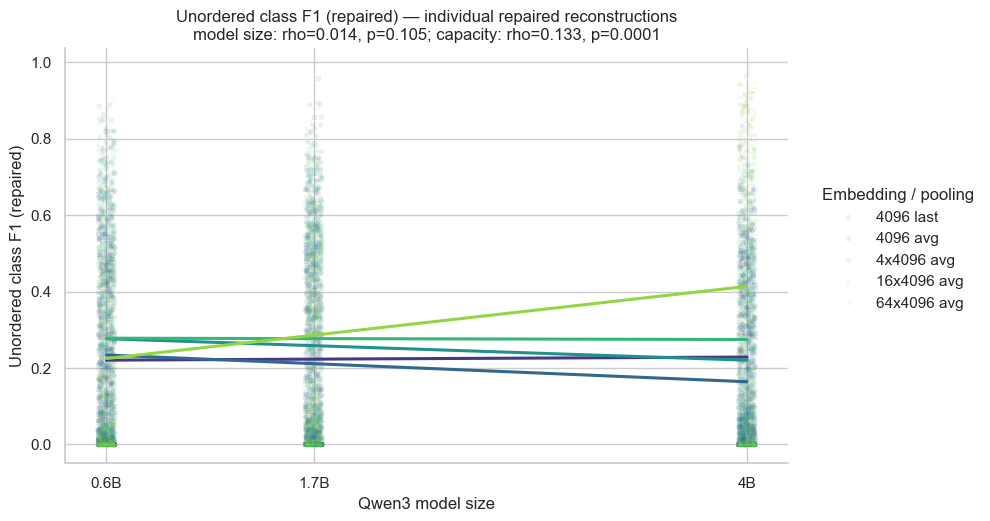

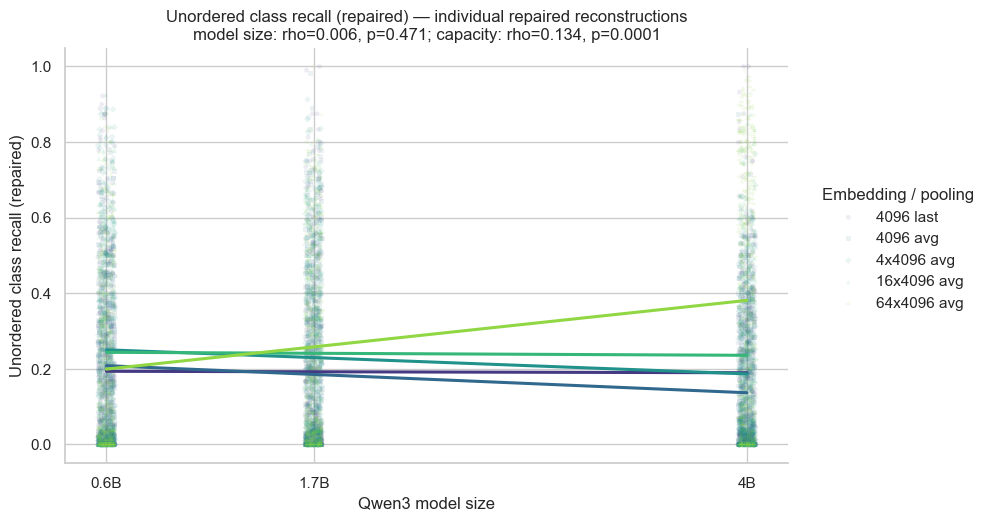

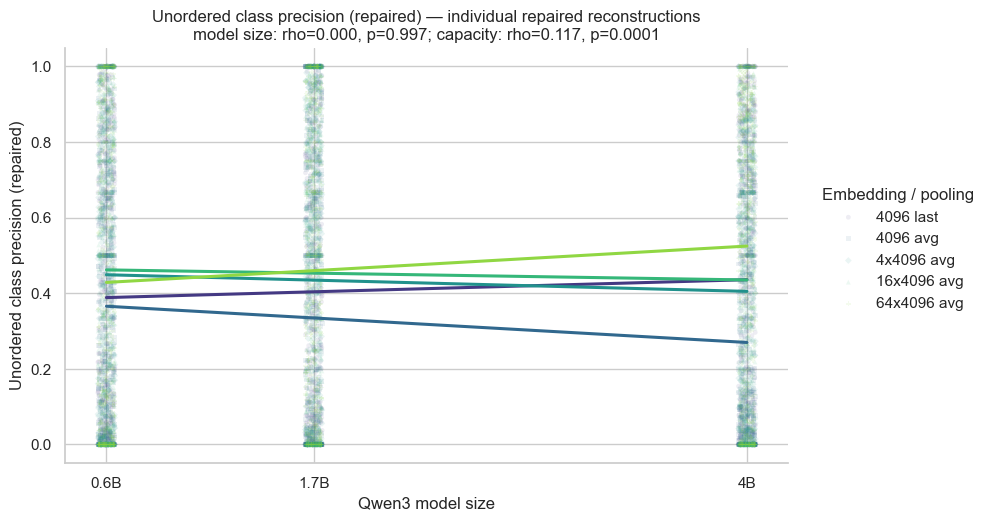

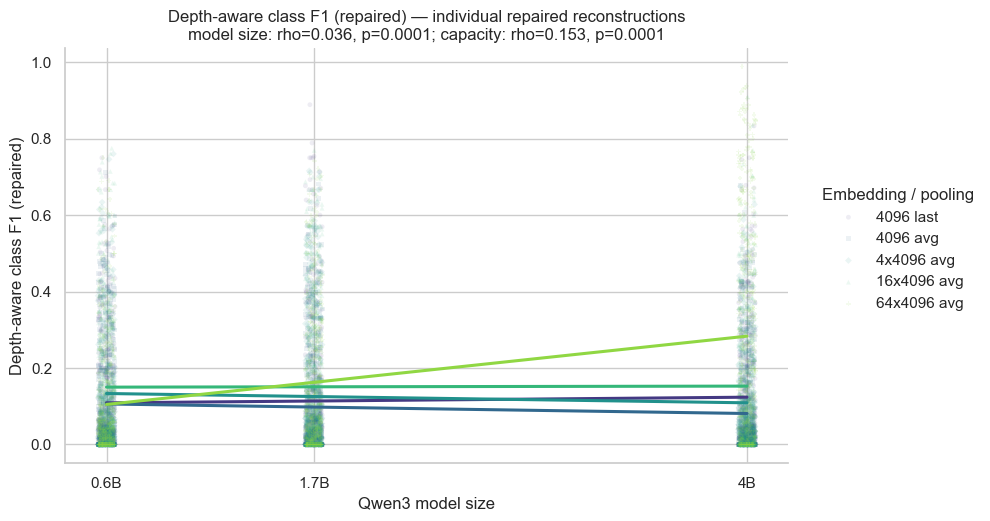

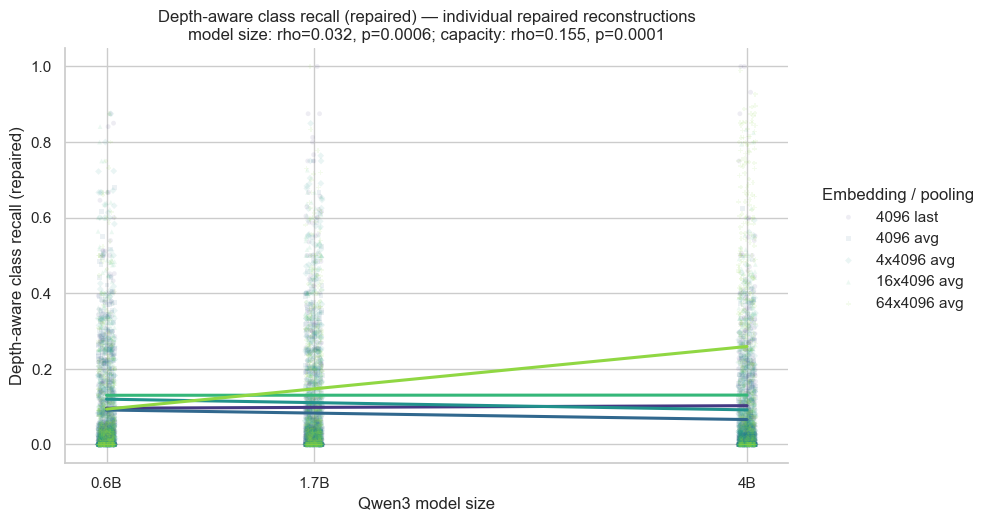

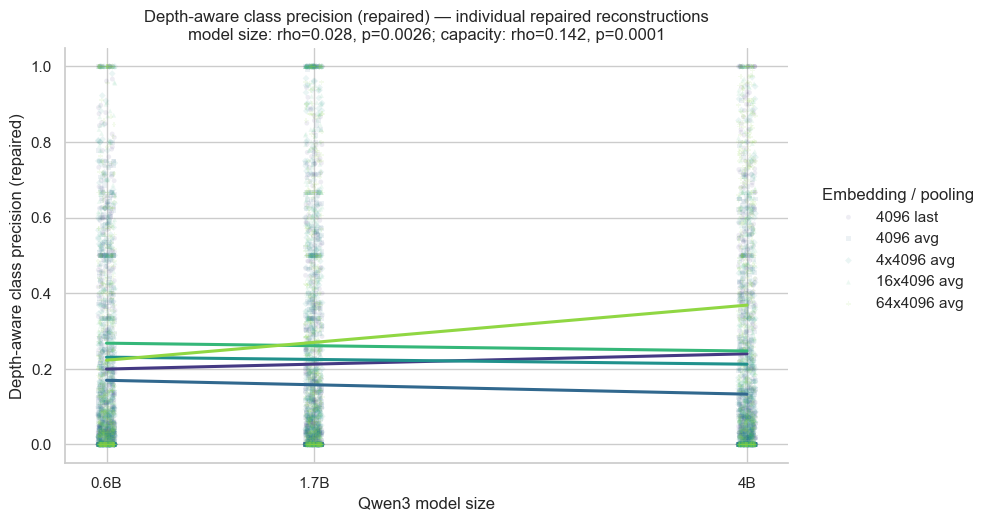

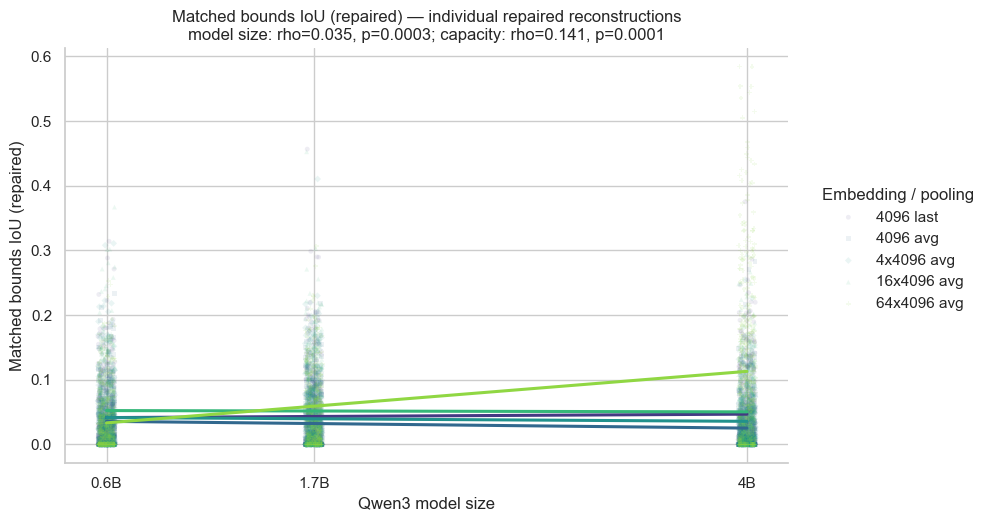

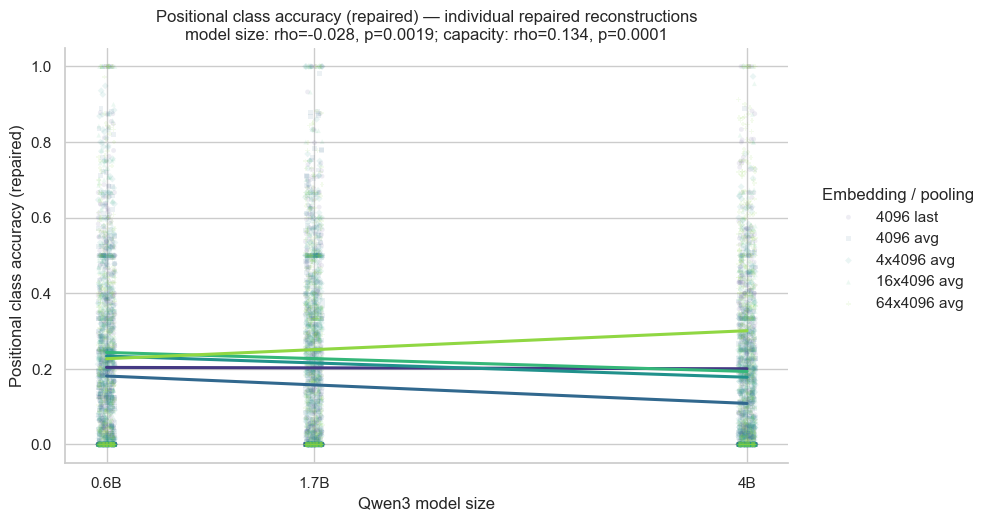

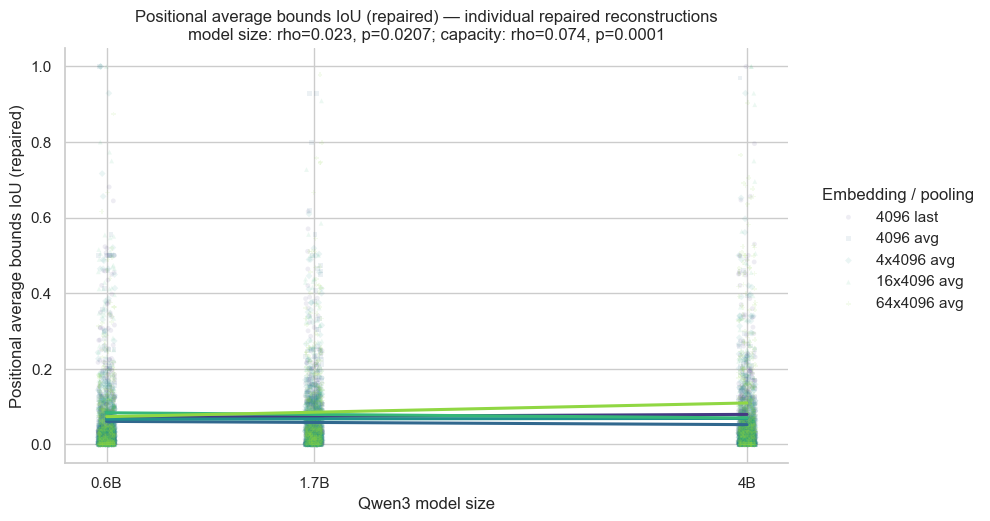

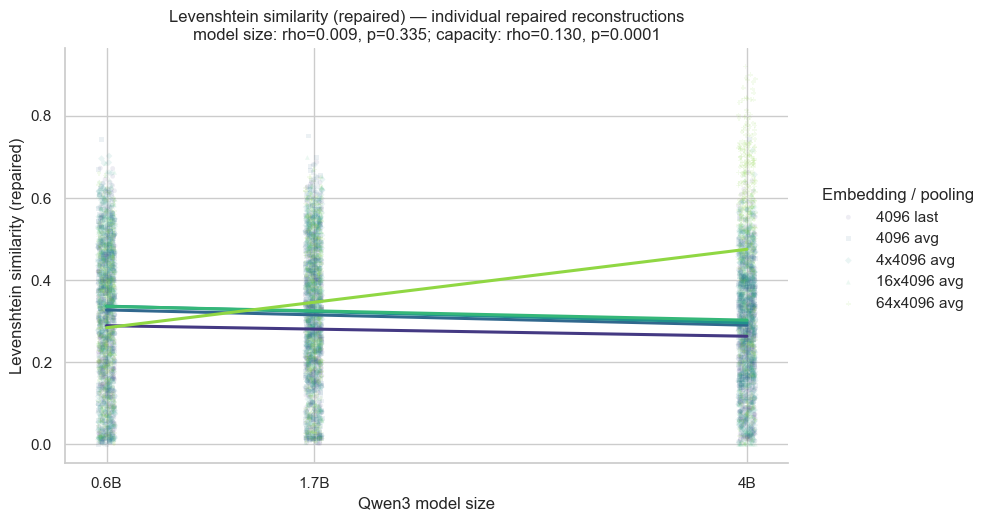

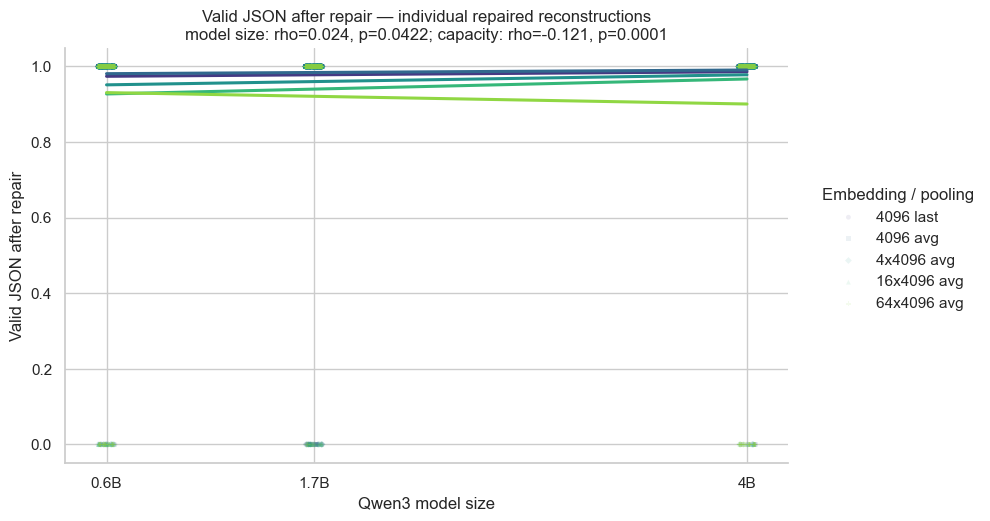

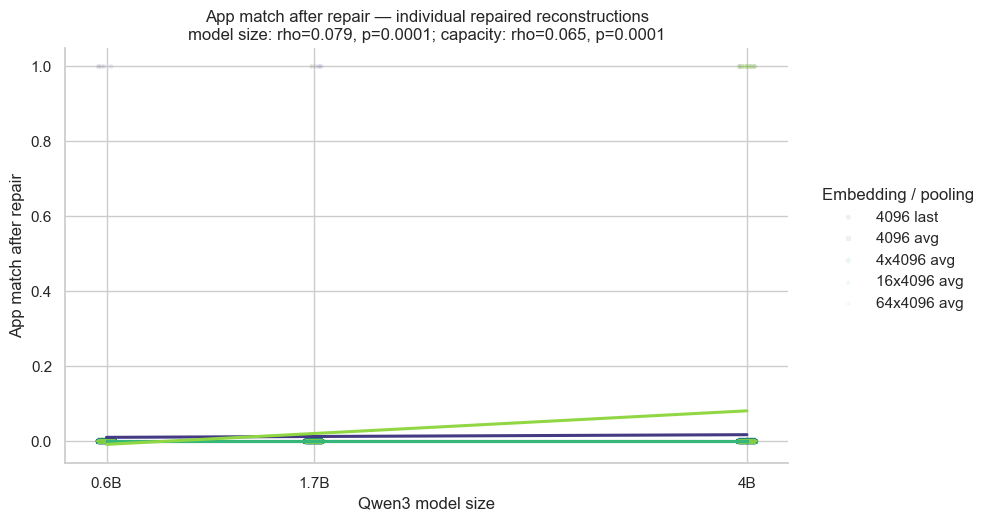

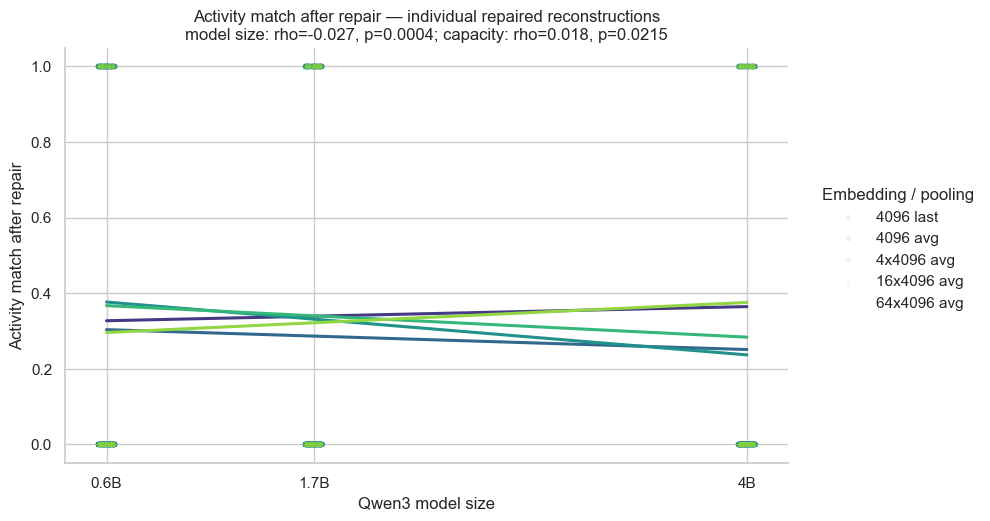

In [11]:
def metric_slug(metric):
    return re.sub(r"[^a-z0-9]+", "_", metric.lower()).strip("_")

plot_data = analysis.copy()
plot_data["pooling_label"] = pd.Categorical(
    plot_data["pooling"].map(POOL_LABELS),
    categories=[POOL_LABELS[p] for p in POOL_ORDER], ordered=True,
)

for metric, label in METRICS.items():
    metric_result = correlations[correlations["metric"].eq(metric)].set_index("predictor")
    size_result = metric_result.loc["Qwen3 model size (B)"]
    capacity_result = metric_result.loc["Embedding dimensions / pooling capacity"]

    g = sns.lmplot(
        data=plot_data, x="model_size_b", y=metric, hue="pooling_label",
        hue_order=[POOL_LABELS[p] for p in POOL_ORDER], palette="viridis",
        markers=["o", "s", "D", "^", "P"], x_jitter=0.045, ci=None,
        height=5.6, aspect=1.55,
        scatter_kws={"s": 12, "alpha": 0.09, "edgecolor": "none", "rasterized": True},
        line_kws={"linewidth": 2.2}, facet_kws={"legend_out": True},
    )
    g.set_axis_labels("Qwen3 model size", label)
    g.ax.set_xticks(MODEL_SIZES, [f"{size:g}B" for size in MODEL_SIZES])
    g.ax.set_title(
        f"{label} — individual repaired reconstructions\n"
        f"model size: rho={size_result.spearman_rho:.3f}, p={size_result.blocked_permutation_p:.3g}; "
        f"capacity: rho={capacity_result.spearman_rho:.3f}, p={capacity_result.blocked_permutation_p:.3g}"
    )
    g._legend.set_title("Embedding / pooling")
    sns.move_legend(g, "center left", bbox_to_anchor=(0.82, 0.5), frameon=False)
    sns.despine(fig=g.figure)
    g.figure.subplots_adjust(right=0.80, top=0.86)

    slug = metric_slug(metric)
    g.figure.savefig(Path("graphics") / f"qwen3_{slug}_lmplot.png", dpi=220, bbox_inches="tight")
    g.figure.savefig(Path("graphics") / f"qwen3_{slug}_lmplot.pdf", bbox_inches="tight")
    if metric == PRIMARY_METRIC:
        for alias in ("qwen3_model_pooling_lmplot", "qwen3_model_pooling_correlation"):
            g.figure.savefig(Path("graphics") / f"{alias}.png", dpi=300, bbox_inches="tight")
            g.figure.savefig(Path("graphics") / f"{alias}.pdf", bbox_inches="tight")
    plt.show()
    plt.close(g.figure)

## Primary result

In [12]:
primary_result = correlations[correlations["metric"].eq(PRIMARY_METRIC)].copy()
primary_result.style.format({"spearman_rho": "{:.4f}", "blocked_permutation_p": "{:.4g}"})

,metric,metric_label,predictor,spearman_rho,blocked_permutation_p,permutations,matched_screens,observations
0,class_unordered_f1_repaired,Unordered class F1 (repaired),Qwen3 model size (B),0.0144,0.1049,10000,453,6795
1,class_unordered_f1_repaired,Unordered class F1 (repaired),Embedding dimensions / pooling capacity,0.1334,9.999e-05,10000,453,6795
